# SimSys Local · Fase 1 · Notebook 01
## Generación y exploración de los datos sintéticos

**Objetivo.** Crear dos datasets de negocios distintos (~10.000 registros cada uno) y comprobar que tienen
la estructura necesaria para un sistema de similitud:

| Dataset | Negocio | ID |
|---|---|---|
| `clientes.xlsx` | Clientes de una plataforma online de apuestas / casino | `PLAYER_ID` |
| `locales.xlsx` | Locales con máquinas de juego (hostelería, salones, bingos) | `LOCAL_ID` |

Cada registro se genera a partir de un **perfil latente** (arquetipo) con sus propias distribuciones, más ruido y
valores nulos. El perfil queda en `SEGMENTO_SIMULADO`: **no se usa para calcular similitudes**, solo para
validar después (notebook 02) que el sistema agrupa lo que debería agrupar.

> Este notebook usa las mismas funciones que `generar_datos.py`, así que da exactamente los mismos ficheros.

In [1]:
import sys
from pathlib import Path

# Permite importar los módulos del proyecto desde la carpeta notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config
from generar_datos import generar_clientes, generar_locales, PERFILES_CLIENTES, PERFILES_LOCALES

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110
print("Raíz del proyecto:", ROOT)

Raíz del proyecto: .


## 1. Parámetros y generación

`REGENERAR = False` reutiliza los Excel si ya existen. Ponlo a `True` para volver a crearlos
(con la misma semilla salen idénticos).

In [2]:
N_CLIENTES = 10_000
N_LOCALES = 10_000
SEED = 42
REGENERAR = False

config.DATA_DIR.mkdir(exist_ok=True)
f_cli = config.PROYECTOS["CLIENTES"]["fichero"]
f_loc = config.PROYECTOS["LOCALES"]["fichero"]

if REGENERAR or not f_cli.exists():
    clientes = generar_clientes(N_CLIENTES, SEED)
    clientes.to_excel(f_cli, index=False, sheet_name="clientes")
    print("✓ clientes.xlsx generado")
else:
    clientes = pd.read_excel(f_cli)
    print("✓ clientes.xlsx leído")

if REGENERAR or not f_loc.exists():
    locales = generar_locales(N_LOCALES, SEED + 1)
    locales.to_excel(f_loc, index=False, sheet_name="locales")
    print("✓ locales.xlsx generado")
else:
    locales = pd.read_excel(f_loc)
    print("✓ locales.xlsx leído")

print(f"Clientes: {clientes.shape} | Locales: {locales.shape}")

✓ clientes.xlsx leído


✓ locales.xlsx leído
Clientes: (10000, 40) | Locales: (10000, 32)


## 2. Perfiles latentes definidos en el generador

In [3]:
def tabla_perfiles(perfiles):
    return pd.DataFrame(perfiles).T.rename_axis("PERFIL")

print("CLIENTES")
display(tabla_perfiles(PERFILES_CLIENTES))
print("LOCALES")
display(tabla_perfiles(PERFILES_LOCALES))

CLIENTES


,peso,edad,prod,acc,dep,rec,ant,live
PERFIL,,,,,,,,
Apostador deportivo casual,0.24,"(34, 9)","(0.85, 0.12, 0.03)",6,45,12,900,0.25
Apostador deportivo intensivo,0.1,"(29, 6)","(0.92, 0.06, 0.02)",26,420,2,1400,0.65
Jugador de slots,0.16,"(45, 11)","(0.05, 0.93, 0.02)",14,160,4,1100,0.02
Casino live alto valor,0.04,"(48, 9)","(0.08, 0.9, 0.02)",22,2600,2,2200,0.05
Pokerista,0.05,"(33, 8)","(0.08, 0.1, 0.82)",18,210,3,1800,0.05
Multiproducto,0.09,"(37, 9)","(0.45, 0.45, 0.1)",16,300,3,1600,0.35
Cliente dormido,0.2,"(40, 12)","(0.55, 0.38, 0.07)",0.4,3,160,1900,0.15
Nuevo registro,0.12,"(27, 7)","(0.7, 0.27, 0.03)",5,35,6,35,0.2


LOCALES


,peso,tipo,zona,m2,maq,rec_maq,horas,visitas,antig
PERFIL,,,,,,,,,
Bar de barrio,0.34,Hostelería,"(Barrio residencial, 0.8)",90,2,900,85,2200,18
Hostelería rural,0.12,Hostelería,"(Rural, 0.9)",110,1.5,650,70,900,25
Hostelería turística,0.08,Hostelería,"(Costa turística, 0.9)",160,2.5,1100,95,4500,12
Salón urbano,0.17,Salón de juego,"(Barrio residencial, 0.6)",260,18,1700,100,5200,9
Salón de paso,0.09,Salón de juego,"(Polígono / Periferia, 0.8)",380,24,1500,110,4800,7
Salón premium,0.06,Salón de juego,"(Centro urbano, 0.85)",520,35,2600,120,9500,5
Bingo tradicional,0.09,Bingo,"(Centro urbano, 0.5)",900,30,1300,80,7000,28
Bingo moderno,0.05,Bingo,"(Polígono / Periferia, 0.6)",1300,55,1900,105,11000,6


## 3. Vista general de cada dataset

In [4]:
def resumen_columnas(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "%_nulos": (100 * df.isna().mean()).round(2),
        "valores_unicos": df.nunique(),
        "ejemplo": df.iloc[0],
    })

display(clientes.head())
display(resumen_columnas(clientes))

,PLAYER_ID,SEGMENTO_SIMULADO,GENERO,EDAD,PROVINCIA,CANAL_ADQUISICION,DISPOSITIVO_PRINCIPAL,MULTICANAL,PRODUCTO_FAVORITO,DEPORTE_FAVORITO,FRANJA_HORARIA_FAVORITA,METODO_DEPOSITO,PCT_APUESTAS_LIVE,DIAS_DESDE_REGISTRO,DIAS_DESDE_ULTIMO_ACCESO,DIAS_DESDE_ULTIMA_APUESTA,DIAS_DESDE_ULTIMO_DEPOSITO,NUM_ACCESOS_30D,NUM_ACCESOS_90D,TOTAL_DEPOSITADO_30D,NUM_DEPOSITOS_30D,TOTAL_DEPOSITADO,TOTAL_RETIRADO,NUM_RETIROS_30D,TURNOVER_SPORTS,TURNOVER_CASINO,TURNOVER_POKER,NGR_SPORTS,NGR_CASINO,NGR_POKER,NGR_30D,BALANCE,NUM_APUESTAS_SPORTS_30D,NUM_SESIONES_CASINO_30D,TICKET_MEDIO,CONTACTABLE_EMAIL,CONTACTABLE_SMS,USA_BONOS,OPEN_RATE_EMAIL,SEGMENTACION_MONETARIA
0,100001,Jugador de slots,F,63.0,A Coruña,Afiliados,Desktop,0,Casino,NaN,Tarde,NaN,0.032,3962,8,11,15,13,39,35.82,1,19379.92,5194.97,0,21.10,179.33,10.55,0.15,8.89,0.53,9.57,37.83,5,12,12.41,1,1,0,0.226,Bajo
1,100002,Nuevo registro,M,31.0,Las Palmas,Paid Social,App móvil,0,Sports,Baloncesto,Noche,NaN,NaN,30,3,5,18,6,17,43.43,4,55.46,6.69,0,185.75,34.83,11.61,-15.26,6.32,0.58,-8.36,15.75,17,1,12.90,1,1,1,0.141,Bajo
2,100003,Apostador deportivo casual,M,38.0,Barcelona,SEO,Web móvil,0,Sports,Fútbol,Noche,Tarjeta,NaN,665,4,7,21,7,13,8.98,2,1000.90,35.28,0,23.45,4.40,1.47,-1.96,0.52,0.07,-1.37,4.99,19,2,1.40,1,1,1,0.178,Bajo
3,100004,Cliente dormido,M,50.0,Tarragona,Retail,Web móvil,1,Casino,NaN,Madrugada,Tarjeta,NaN,2076,83,100,122,0,0,0.00,0,1924.48,582.47,0,0.00,0.00,0.00,0.00,0.00,0.00,0.00,3.86,0,0,0.00,1,1,0,0.095,Sin actividad
4,100005,Jugador de slots,F,34.0,Madrid,TV / Patrocinio,App móvil,0,Casino,NaN,Madrugada,Tarjeta,0.183,841,1,3,5,17,40,114.58,2,1565.09,930.21,1,65.79,559.24,32.90,16.83,-26.71,1.64,-8.24,10.11,8,23,21.22,1,0,1,0.482,Medio


,dtype,nulos,%_nulos,valores_unicos,ejemplo
PLAYER_ID,int64,0,0.00,10000,100001
SEGMENTO_SIMULADO,str,0,0.00,8,Jugador de slots
GENERO,str,0,0.00,2,F
EDAD,float64,192,1.92,62,63.0
PROVINCIA,str,94,0.94,20,A Coruña
CANAL_ADQUISICION,str,0,0.00,5,Afiliados
DISPOSITIVO_PRINCIPAL,str,0,0.00,3,Desktop
MULTICANAL,int64,0,0.00,2,0
PRODUCTO_FAVORITO,str,0,0.00,3,Casino
DEPORTE_FAVORITO,str,3226,32.26,5,NaN


In [5]:
display(locales.head())
display(resumen_columnas(locales))

,LOCAL_ID,SEGMENTO_SIMULADO,TIPO_LOCAL,TIPO_ZONA,PROVINCIA,COMUNIDAD_AUTONOMA,NIVEL_SOCIOECONOMICO_ZONA,POBLACION_ZONA_1KM,COMPETIDORES_500M,SUPERFICIE_M2,AFORO,ANTIGUEDAD_ANIOS,NUM_MAQUINAS_B,NUM_EMPLEADOS,HORAS_APERTURA_SEMANA,HORARIO,TIENE_APUESTAS_DEPORTIVAS,NUM_TERMINALES_APUESTAS,TIENE_RESTAURACION,TIENE_TERRAZA,TIENE_PARKING,PROGRAMA_FIDELIZACION,PROVEEDOR_MAQUINAS,RECAUDACION_MEDIA_MENSUAL,VARIACION_RECAUDACION_YOY,RECAUDACION_ULTIMO_MES,RECAUDACION_POR_MAQUINA,VISITAS_MES,TICKET_MEDIO,PCT_OCUPACION_MEDIA,INCIDENCIAS_TECNICAS_90D,DIAS_DESDE_ULTIMO_RECANJE
0,5001,Salón premium,Salón de juego,Centro urbano,Baleares,Baleares,Alto,24016.0,3,559,371,2.5,21,2,110,Estándar,0,0,0,0,0,1,Proveedor B,68558.93,-0.086,60342.74,3264.71,11424,20.50,0.712,3,235
1,5002,Bar de barrio,Hostelería,Rural,Madrid,Madrid,Medio,1689.0,0,57,47,46.7,3,2,72,Reducido,0,0,1,1,0,0,Proveedor A,1510.07,-0.115,1182.18,503.36,3208,1.21,0.316,0,240
2,5003,Bar de barrio,Hostelería,Barrio residencial,A Coruña,Galicia,Medio,47277.0,2,66,57,13.4,1,2,77,Reducido,0,0,1,1,0,0,Proveedor D,609.69,0.061,635.89,609.69,3467,0.68,0.585,0,78
3,5004,Hostelería turística,Hostelería,Centro urbano,Baleares,Baleares,Medio,50725.0,4,105,108,2.1,3,1,103,Estándar,0,0,1,0,0,0,Proveedor C,5808.19,-0.188,4594.37,1936.06,2941,6.12,0.429,0,171
4,5005,Bar de barrio,Hostelería,Costa turística,Zaragoza,Aragón,Bajo,9491.0,2,101,74,4.6,3,2,84,Estándar,0,0,1,0,0,0,Proveedor B,1007.47,-0.087,849.43,335.82,3190,0.96,0.389,0,202


,dtype,nulos,%_nulos,valores_unicos,ejemplo
LOCAL_ID,int64,0,0.00,10000,5001
SEGMENTO_SIMULADO,str,0,0.00,8,Salón premium
TIPO_LOCAL,str,0,0.00,3,Salón de juego
TIPO_ZONA,str,0,0.00,5,Centro urbano
PROVINCIA,str,0,0.00,20,Baleares
COMUNIDAD_AUTONOMA,str,0,0.00,14,Baleares
NIVEL_SOCIOECONOMICO_ZONA,str,0,0.00,3,Alto
POBLACION_ZONA_1KM,float64,260,2.60,8441,24016.0
COMPETIDORES_500M,int64,0,0.00,14,3
SUPERFICIE_M2,int64,0,0.00,1369,559


## 4. Valores nulos

Los nulos se han inyectado a propósito para que el preprocesado tenga trabajo real:
aleatorios (EDAD, PROVINCIA…) y estructurales (`DEPORTE_FAVORITO` vacío en quien no apuesta a deportes,
`OPEN_RATE_EMAIL` vacío en no contactables).

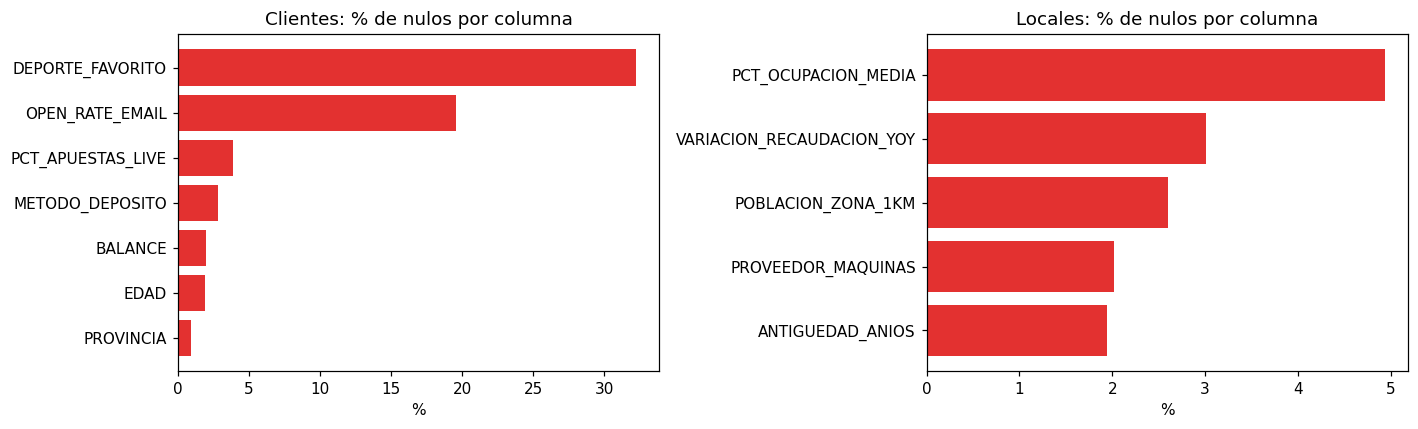

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (nombre, df) in zip(axes, [("Clientes", clientes), ("Locales", locales)]):
    nulos = (100 * df.isna().mean()).sort_values()
    nulos = nulos[nulos > 0]
    ax.barh(nulos.index, nulos.values, color="#E33130")
    ax.set_title(f"{nombre}: % de nulos por columna")
    ax.set_xlabel("%")
plt.tight_layout()
plt.show()

## 5. Tamaño de los segmentos simulados

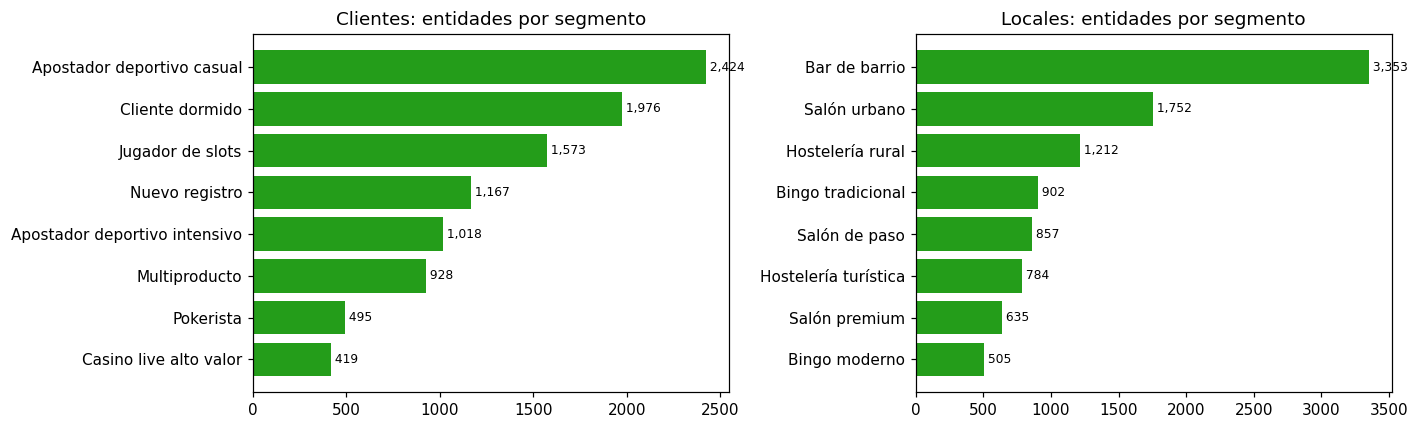

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (nombre, df) in zip(axes, [("Clientes", clientes), ("Locales", locales)]):
    vc = df["SEGMENTO_SIMULADO"].value_counts().sort_values()
    ax.barh(vc.index, vc.values, color="#249D1A")
    ax.set_title(f"{nombre}: entidades por segmento")
    for i, v in enumerate(vc.values):
        ax.text(v, i, f" {v:,}", va="center", fontsize=8)
plt.tight_layout()
plt.show()

## 6. ¿Los segmentos se diferencian en las variables?

Si los perfiles no fueran distinguibles en los datos, ningún sistema de similitud podría recuperarlos.
Miramos medianas por segmento de algunas variables clave y su dispersión.

In [8]:
vars_cli = ["EDAD", "DIAS_DESDE_REGISTRO", "DIAS_DESDE_ULTIMO_ACCESO", "NUM_ACCESOS_30D",
            "TOTAL_DEPOSITADO_30D", "TURNOVER_SPORTS", "TURNOVER_CASINO", "PCT_APUESTAS_LIVE"]
(clientes.groupby("SEGMENTO_SIMULADO")[vars_cli].median().round(1)
 .style.background_gradient(axis=0, cmap="Greens"))

,EDAD,DIAS_DESDE_REGISTRO,DIAS_DESDE_ULTIMO_ACCESO,NUM_ACCESOS_30D,TOTAL_DEPOSITADO_30D,TURNOVER_SPORTS,TURNOVER_CASINO,PCT_APUESTAS_LIVE
SEGMENTO_SIMULADO,,,,,,,,
Apostador deportivo casual,34.000000,779.000000,8.000000,6.000000,29.800000,80.600000,21.100000,0.200000
Apostador deportivo intensivo,29.000000,1235.500000,1.000000,26.000000,282.700000,826.500000,188.200000,0.700000
Casino live alto valor,48.000000,1988.000000,1.000000,21.000000,1688.500000,752.900000,5132.300000,0.100000
Cliente dormido,40.000000,1670.000000,115.000000,0.000000,0.000000,0.000000,0.000000,0.100000
Jugador de slots,46.000000,983.000000,3.000000,14.000000,109.800000,47.200000,349.700000,0.000000
Multiproducto,37.000000,1333.500000,2.000000,16.000000,196.100000,364.600000,364.600000,0.400000
Nuevo registro,27.000000,30.000000,4.000000,5.000000,25.000000,49.200000,21.600000,0.200000
Pokerista,32.000000,1602.000000,2.000000,18.000000,139.600000,67.100000,105.700000,0.100000


In [9]:
vars_loc = ["SUPERFICIE_M2", "NUM_MAQUINAS_B", "HORAS_APERTURA_SEMANA", "RECAUDACION_MEDIA_MENSUAL",
            "RECAUDACION_POR_MAQUINA", "VISITAS_MES", "POBLACION_ZONA_1KM", "ANTIGUEDAD_ANIOS"]
(locales.groupby("SEGMENTO_SIMULADO")[vars_loc].median().round(1)
 .style.background_gradient(axis=0, cmap="Reds"))

,SUPERFICIE_M2,NUM_MAQUINAS_B,HORAS_APERTURA_SEMANA,RECAUDACION_MEDIA_MENSUAL,RECAUDACION_POR_MAQUINA,VISITAS_MES,POBLACION_ZONA_1KM,ANTIGUEDAD_ANIOS
SEGMENTO_SIMULADO,,,,,,,,
Bar de barrio,86.000000,2.000000,85.000000,1455.200000,821.700000,2061.000000,20953.000000,15.000000
Bingo moderno,1261.000000,54.000000,105.000000,89443.200000,1708.000000,9906.000000,10116.500000,5.000000
Bingo tradicional,854.000000,30.000000,80.000000,35935.900000,1226.400000,6651.000000,23979.000000,24.800000
Hostelería rural,104.000000,1.000000,69.000000,871.700000,626.900000,831.000000,1938.000000,20.800000
Hostelería turística,151.500000,3.000000,95.000000,2263.500000,1022.000000,4239.500000,15297.500000,10.400000
Salón de paso,364.000000,24.000000,110.000000,32583.600000,1383.700000,4496.000000,9392.500000,5.500000
Salón premium,511.000000,34.000000,121.000000,86195.600000,2559.200000,8921.000000,34908.000000,4.300000
Salón urbano,252.000000,18.000000,100.000000,27355.600000,1550.800000,4886.500000,20074.000000,7.800000


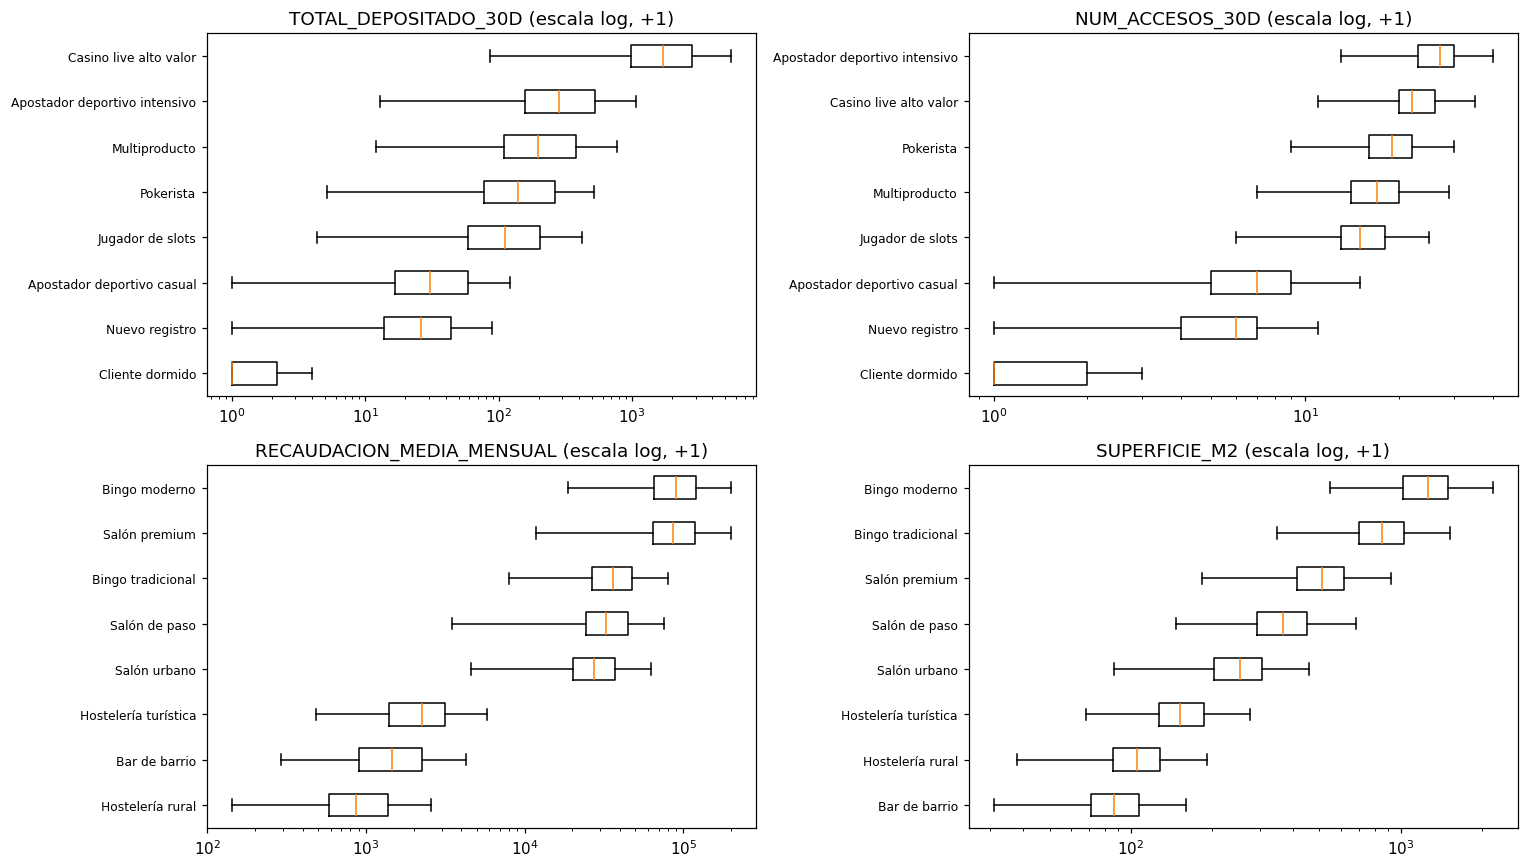

In [10]:
def boxplot_por_segmento(df, col, ax, log=True):
    orden = df.groupby("SEGMENTO_SIMULADO")[col].median().sort_values().index
    datos = [df.loc[df["SEGMENTO_SIMULADO"] == s, col].dropna().clip(lower=0) + (1 if log else 0) for s in orden]
    ax.boxplot(datos, vert=False, showfliers=False)
    ax.set_yticks(range(1, len(orden) + 1), orden, fontsize=8)
    if log:
        ax.set_xscale("log")
    ax.set_title(col + (" (escala log, +1)" if log else ""))

fig, axes = plt.subplots(2, 2, figsize=(14, 8))
boxplot_por_segmento(clientes, "TOTAL_DEPOSITADO_30D", axes[0, 0])
boxplot_por_segmento(clientes, "NUM_ACCESOS_30D", axes[0, 1])
boxplot_por_segmento(locales, "RECAUDACION_MEDIA_MENSUAL", axes[1, 0])
boxplot_por_segmento(locales, "SUPERFICIE_M2", axes[1, 1])
plt.tight_layout()
plt.show()

### Variables categóricas por segmento (% por fila)

In [11]:
display((pd.crosstab(clientes["SEGMENTO_SIMULADO"], clientes["PRODUCTO_FAVORITO"], normalize="index") * 100)
        .round(1).style.background_gradient(axis=1, cmap="Greens"))
display((pd.crosstab(locales["SEGMENTO_SIMULADO"], locales["TIPO_ZONA"], normalize="index") * 100)
        .round(1).style.background_gradient(axis=1, cmap="Reds"))

PRODUCTO_FAVORITO,Casino,Poker,Sports
SEGMENTO_SIMULADO,,,
Apostador deportivo casual,11.300000,3.300000,85.400000
Apostador deportivo intensivo,7.500000,2.900000,89.600000
Casino live alto valor,90.000000,2.400000,7.600000
Cliente dormido,38.200000,6.900000,55.000000
Jugador de slots,93.900000,1.800000,4.300000
Multiproducto,44.500000,10.600000,44.900000
Nuevo registro,27.600000,2.600000,69.800000
Pokerista,9.700000,82.200000,8.100000


TIPO_ZONA,Barrio residencial,Centro urbano,Costa turística,Polígono / Periferia,Rural
SEGMENTO_SIMULADO,,,,,
Bar de barrio,79.600000,5.000000,5.000000,5.300000,5.100000
Bingo moderno,10.500000,8.700000,11.900000,59.800000,9.100000
Bingo tradicional,12.600000,49.200000,13.200000,12.300000,12.600000
Hostelería rural,2.800000,2.300000,2.600000,3.400000,88.900000
Hostelería turística,3.400000,2.800000,89.700000,1.900000,2.200000
Salón de paso,4.700000,4.300000,4.900000,80.500000,5.600000
Salón premium,3.100000,86.300000,3.800000,3.000000,3.800000
Salón urbano,59.700000,10.500000,10.000000,9.400000,10.400000


## 7. Correlaciones entre variables numéricas

Útil para la memoria: hay grupos de variables muy correlacionadas (depósitos ↔ turnover, superficie ↔ aforo ↔ máquinas).
En una métrica como el coseno eso da más peso implícito a esos "bloques". Es un punto a tener en cuenta
cuando en fases posteriores se definan ejes temáticos.

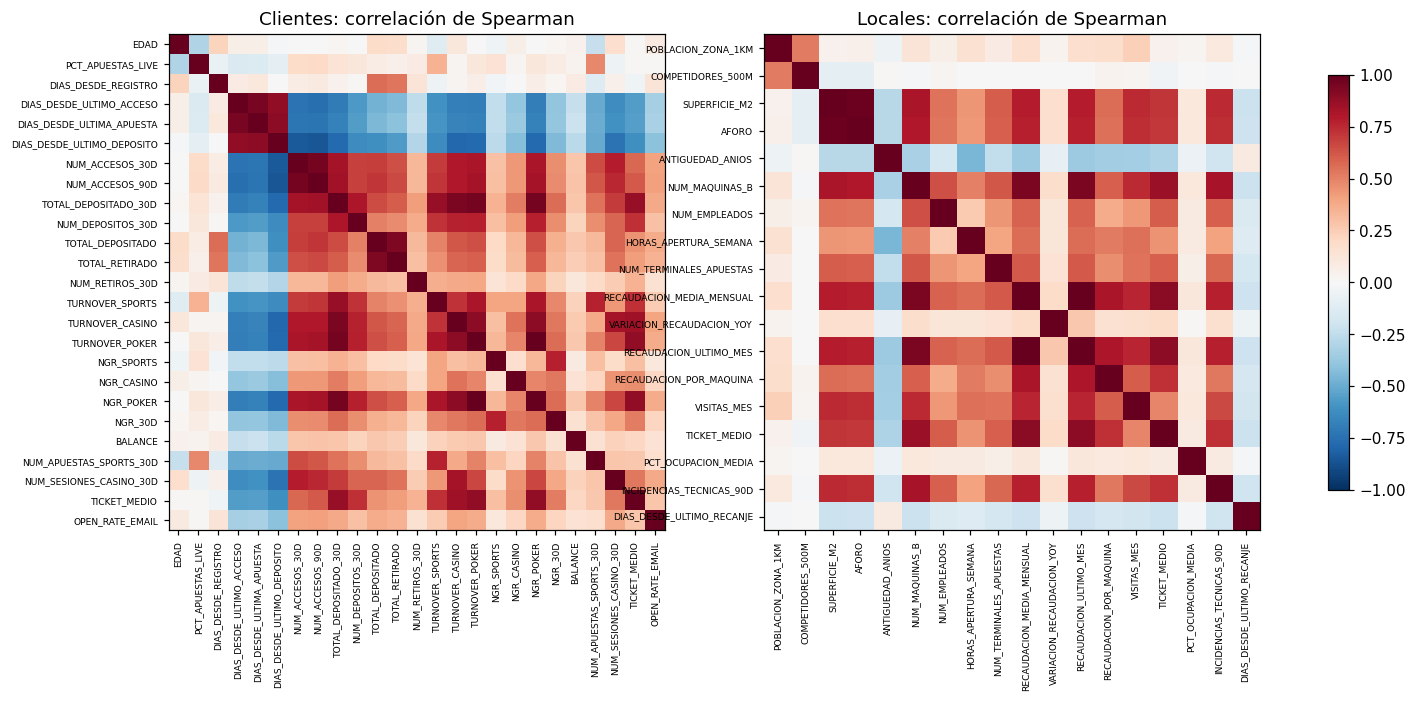

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (nombre, df) in zip(axes, [("Clientes", clientes), ("Locales", locales)]):
    num = df.select_dtypes("number").drop(columns=[c for c in ["PLAYER_ID", "LOCAL_ID"] if c in df])
    num = num.loc[:, num.nunique() > 2]
    corr = num.corr(method="spearman")
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=6)
    ax.set_yticks(range(len(corr)), corr.columns, fontsize=6)
    ax.set_title(f"{nombre}: correlación de Spearman")
fig.colorbar(im, ax=axes, shrink=0.7)
plt.show()

## 8. Conclusiones

- Los dos datasets tienen **~10.000 entidades**, mezcla de variables **numéricas, categóricas y booleanas**, y nulos
  aleatorios y estructurales: el mismo tipo de problema que la ficha de cliente real.
- Los segmentos simulados **se diferencian** en valor, actividad, tamaño y ubicación, pero **se solapan**
  (p. ej., *Salón urbano* y *Salón de paso*; *Apostador casual* y *Nuevo registro*). Esto evita un problema trivial.
- Hay bloques de variables correlacionadas, a considerar al diseñar ejes.

**Siguiente:** `02_similitudes_y_validacion.ipynb`.